In [2]:
# STEP 1: IMPORT LIBRARIES

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Upload dataset
from google.colab import files
uploaded = files.upload()

# Read dataset
filename = list(uploaded.keys())[0]
df = pd.read_csv(filename)

print("Dataset loaded successfully!")

Saving Unemployment in India.csv to Unemployment in India.csv
Dataset loaded successfully!


In [3]:
# STEP 2: DATASET INSPECTION

# Display first five rows
display(df.head())

# Dataset shape
print("Dataset Shape:", df.shape)

# Column names
print("\nColumn Names:")
print(df.columns.tolist())

# Data types
print("\nData Types:")
print(df.dtypes)

# Missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Duplicate records
print("\nDuplicate Rows:", df.duplicated().sum())

,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
0,Andhra Pradesh,31-05-2019,Monthly,3.65,11999139.0,43.24,Rural
1,Andhra Pradesh,30-06-2019,Monthly,3.05,11755881.0,42.05,Rural
2,Andhra Pradesh,31-07-2019,Monthly,3.75,12086707.0,43.50,Rural
3,Andhra Pradesh,31-08-2019,Monthly,3.32,12285693.0,43.97,Rural
4,Andhra Pradesh,30-09-2019,Monthly,5.17,12256762.0,44.68,Rural


Dataset Shape: (768, 7)

Column Names:
['Region', ' Date', ' Frequency', ' Estimated Unemployment Rate (%)', ' Estimated Employed', ' Estimated Labour Participation Rate (%)', 'Area']

Data Types:
Region                                       object
 Date                                        object
 Frequency                                   object
 Estimated Unemployment Rate (%)            float64
 Estimated Employed                         float64
 Estimated Labour Participation Rate (%)    float64
Area                                         object
dtype: object

Missing Values:
Region                                      28
 Date                                       28
 Frequency                                  28
 Estimated Unemployment Rate (%)            28
 Estimated Employed                         28
 Estimated Labour Participation Rate (%)    28
Area                                        28
dtype: int64

Duplicate Rows: 27


In [4]:
# STEP 3: DATA CLEANING

# Remove extra spaces
df.columns = df.columns.str.strip()

for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].str.strip()

# Convert Date column
df["Date"] = pd.to_datetime(
    df["Date"], dayfirst=True, errors="coerce"
)

# Convert numerical columns
numeric_cols = [
    "Estimated Unemployment Rate (%)",
    "Estimated Employed",
    "Estimated Labour Participation Rate (%)"
]

for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Remove duplicates
df = df.drop_duplicates()

# Remove invalid dates
df = df.dropna(subset=["Date"])

print("Data cleaning completed!")
print("New shape:", df.shape)

print("\nMissing Values:")
print(df.isnull().sum())

Data cleaning completed!
New shape: (740, 7)

Missing Values:
Region                                     0
Date                                       0
Frequency                                  0
Estimated Unemployment Rate (%)            0
Estimated Employed                         0
Estimated Labour Participation Rate (%)    0
Area                                       0
dtype: int64


,Estimated Unemployment Rate (%)
Region,
Tripura,28.35
Haryana,26.28
Jharkhand,20.58
Bihar,18.92
Himachal Pradesh,18.54
Delhi,16.50
Jammu & Kashmir,16.19
Chandigarh,15.99
Rajasthan,14.06


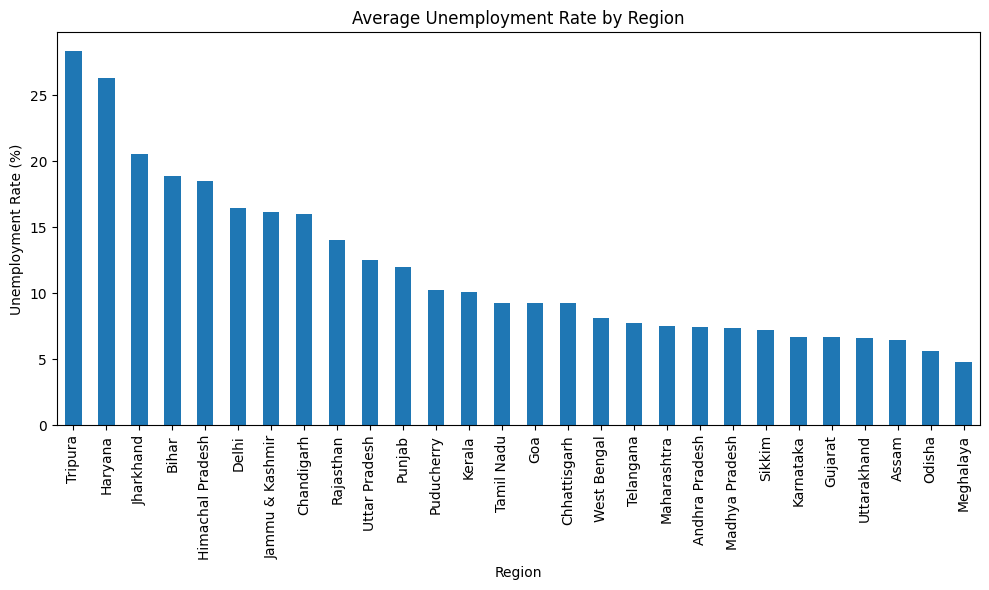

In [5]:
# STEP 4: REGION-WISE ANALYSIS

region_avg = (
    df.groupby("Region")["Estimated Unemployment Rate (%)"]
    .mean()
    .sort_values(ascending=False)
)

display(region_avg.round(2))

plt.figure(figsize=(10, 6))
region_avg.plot(kind="bar")

plt.title("Average Unemployment Rate by Region")
plt.xlabel("Region")
plt.ylabel("Unemployment Rate (%)")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

Observation: The chart compares average unemployment rates across different Indian regions and identifies regional differences in unemployment.

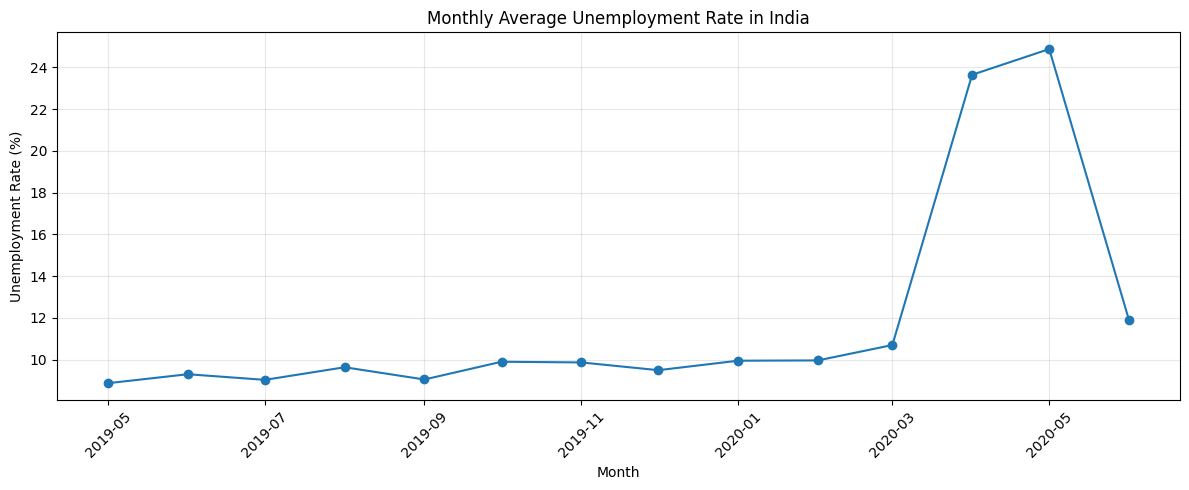

In [6]:
# STEP 5: MONTH-WISE ANALYSIS

df["Month"] = df["Date"].dt.to_period("M").dt.to_timestamp()

monthly_avg = df.groupby("Month")[
    "Estimated Unemployment Rate (%)"
].mean()

plt.figure(figsize=(12, 5))

plt.plot(monthly_avg.index, monthly_avg.values, marker="o")

plt.title("Monthly Average Unemployment Rate in India")
plt.xlabel("Month")
plt.ylabel("Unemployment Rate (%)")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Observation: The monthly trend shows fluctuations in unemployment rates over time. Peaks indicate months with higher average unemployment, while declines indicate lower average unemployment.

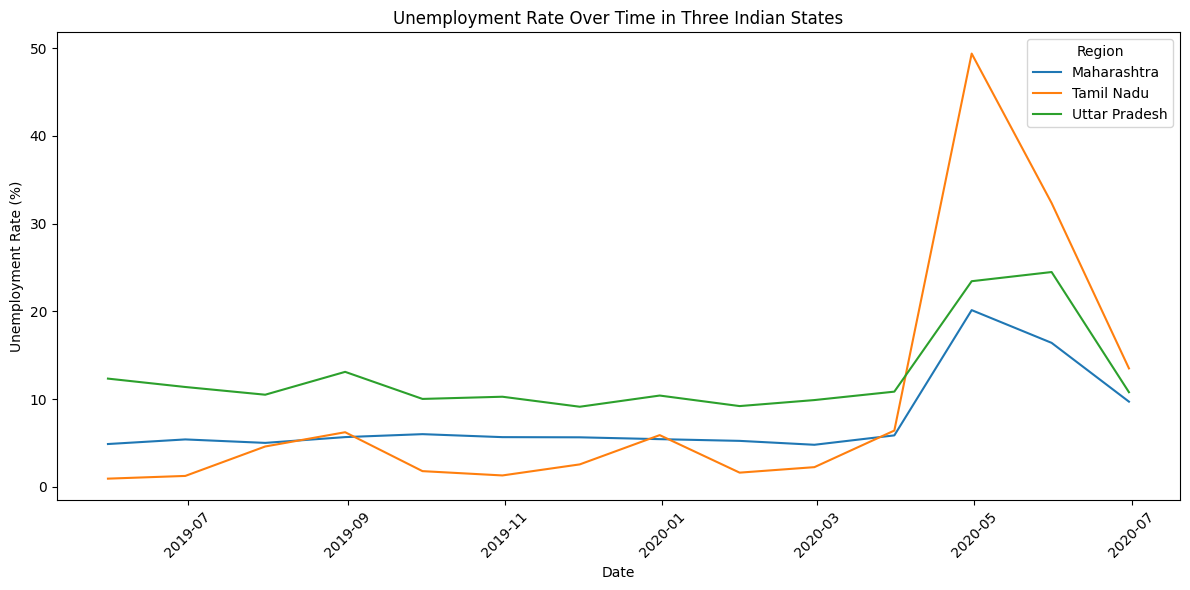

In [7]:
# STEP 6: THREE-STATE COMPARISON

states = ["Maharashtra", "Uttar Pradesh", "Tamil Nadu"]

state_data = df[df["Region"].isin(states)]

plt.figure(figsize=(12, 6))

sns.lineplot(
    data=state_data,
    x="Date",
    y="Estimated Unemployment Rate (%)",
    hue="Region",
    estimator="mean",
    errorbar=None
)

plt.title("Unemployment Rate Over Time in Three Indian States")
plt.xlabel("Date")
plt.ylabel("Unemployment Rate (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Observation: This chart compares unemployment trends across three Indian states and highlights differences in their unemployment patterns over time.

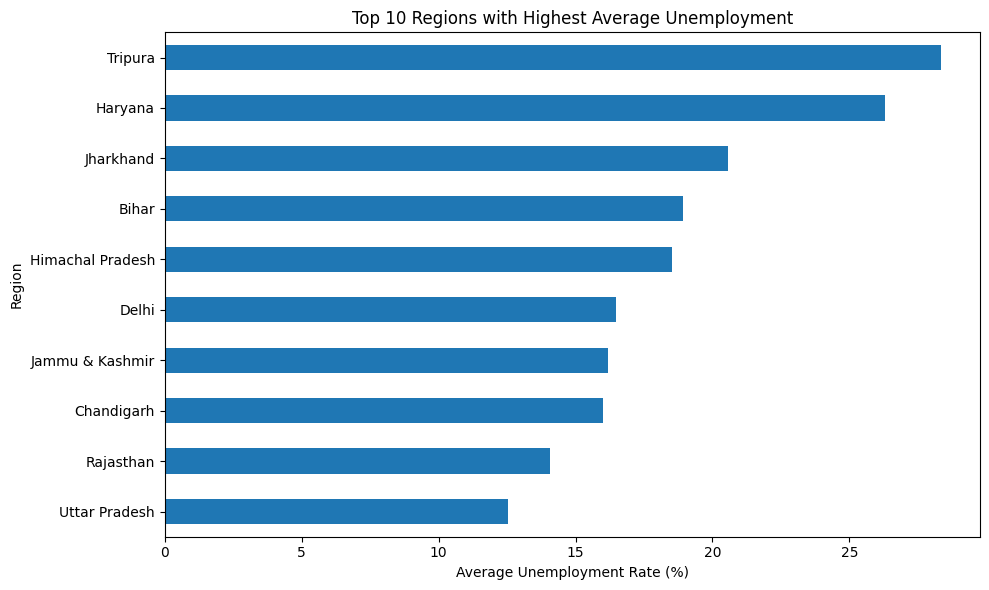

In [8]:
# STEP 7: TOP 10 REGIONS

top_10 = (
    df.groupby("Region")["Estimated Unemployment Rate (%)"]
    .mean()
    .nlargest(10)
    .sort_values()
)

plt.figure(figsize=(10, 6))

top_10.plot(kind="barh")

plt.title("Top 10 Regions with Highest Average Unemployment")
plt.xlabel("Average Unemployment Rate (%)")
plt.ylabel("Region")
plt.tight_layout()
plt.show()

Observation: The bar chart identifies the ten regions with the highest average unemployment rates in the dataset.

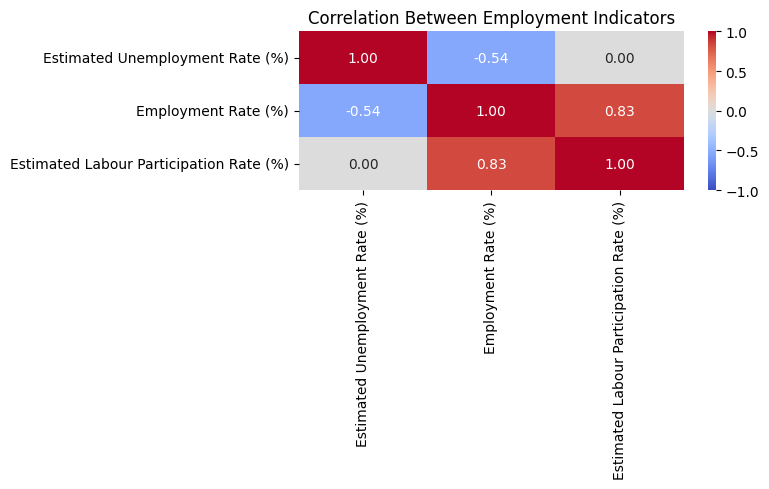

In [9]:
# STEP 8: CORRELATION HEATMAP

# Derive estimated employment-to-population rate
df["Employment Rate (%)"] = (
    df["Estimated Labour Participation Rate (%)"] *
    (100 - df["Estimated Unemployment Rate (%)"]) / 100
)

correlation_cols = [
    "Estimated Unemployment Rate (%)",
    "Employment Rate (%)",
    "Estimated Labour Participation Rate (%)"
]

correlation_matrix = df[correlation_cols].corr()

plt.figure(figsize=(8, 5))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Between Employment Indicators")
plt.tight_layout()
plt.show()

Observation: The heatmap illustrates the correlation between unemployment, estimated employment, and labour force participation rates. Positive and negative values indicate the direction of relationships.

   Pre-COVID  COVID Onward
0       9.51         17.77


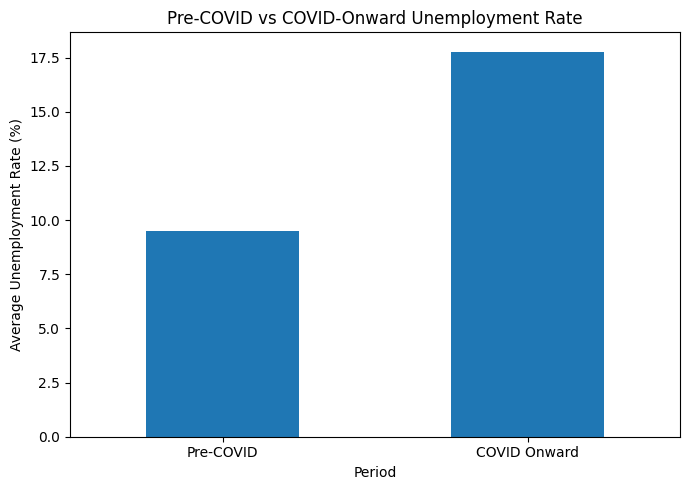

In [10]:
# STEP 9: COVID-19 IMPACT ANALYSIS

pre_covid = df[df["Date"] < "2020-03-01"]
covid_onward = df[df["Date"] >= "2020-03-01"]

comparison = pd.DataFrame({
    "Pre-COVID": [
        pre_covid["Estimated Unemployment Rate (%)"].mean()
    ],
    "COVID Onward": [
        covid_onward["Estimated Unemployment Rate (%)"].mean()
    ]
})

print(comparison.round(2))

comparison.T.plot(
    kind="bar",
    legend=False,
    figsize=(7, 5)
)

plt.title("Pre-COVID vs COVID-Onward Unemployment Rate")
plt.ylabel("Average Unemployment Rate (%)")
plt.xlabel("Period")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Observation: The comparison shows the difference in average unemployment rates before March 2020 and from March 2020 onward. It helps examine unemployment changes during the pandemic period.

# Conclusion

The Unemployment Analysis project explores unemployment trends across different regions of India using Python.

The project uses Pandas for data cleaning and analysis, and Matplotlib and Seaborn for visualization.

The analysis covers region-wise averages, monthly trends, state-wise comparisons, correlation between employment indicators, and pre-COVID versus COVID-onward unemployment rates.

The visualizations help identify regional differences and changes in unemployment over time. This analysis provides insights into the possible impact of the COVID-19 pandemic on employment conditions in India.